# Employee Data Analysis — Data Cleaning, EDA & Business Story

## Project Overview

This project analyzes a **messy employee dataset** containing employee demographics, department/region, employment status, joining date, salary, performance, and remote-work information.

1. DATASET Choose any dataset different from Titanic. Minimum 500 rows, minimum 5 columns, mix of numeric and categorical columns.
2. DATA LOADING AND CLEANING Load the dataset using Pandas. Handle missing values, duplicates and data type issues. Show your cleaning steps clearly.
3. EXPLORATORY DATA ANALYSIS At least 3 GroupBy analyses with written commentary. Correlation matrix. Outlier detection on at least one column.
4. VISUALISATION Minimum 4 charts using Matplotlib or Seaborn. At least one subplot grid. All charts must have titles and labelled axes.
5. BUSINESS STORY Follow the visual storytelling structure: context, finding, deeper finding, recommendation. Written in plain English using Markdown cells.
6. CAUSE/EFFECT/BUSINESS IMPACT One Markdown cell applying the framework to your main finding.


## 1. DATA LOADING

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score


# Load the CSV file
df = pd.read_csv(r"C:\Users\USER\Documents\messy_employee_data.csv")
df.head()

print("Dataset shape:", df.shape)


Dataset shape: (1020, 12)


In [2]:
# Initial structure and data types
df.info()

print("\nMissing values:")
display(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Employee_ID        1020 non-null   object 
 1   First_Name         1020 non-null   object 
 2   Last_Name          1020 non-null   object 
 3   Age                809 non-null    float64
 4   Department_Region  1020 non-null   object 
 5   Status             1020 non-null   object 
 6   Join_Date          1020 non-null   object 
 7   Salary             996 non-null    float64
 8   Email              1020 non-null   object 
 9   Phone              1020 non-null   int64  
 10  Performance_Score  1020 non-null   object 
 11  Remote_Work        1020 non-null   bool   
dtypes: bool(1), float64(2), int64(1), object(8)
memory usage: 88.8+ KB

Missing values:


Employee_ID            0
First_Name             0
Last_Name              0
Age                  211
Department_Region      0
Status                 0
Join_Date              0
Salary                24
Email                  0
Phone                  0
Performance_Score      0
Remote_Work            0
dtype: int64


Duplicate rows: 0


## 2. DATA CLEANING

The raw dataset contains several issues that need attention:

1. **Age** contains missing values.
2. **Salary** contains missing values.
3. **Join_Date** is stored as text instead of a date.
4. **Phone** values contain negative numbers, so they need to be treated as contact strings rather than mathematical values.
5. We also check for duplicate employee IDs and duplicate rows before analysis.


In [3]:
# Work on a copy
clean_df = df.copy()

# 1. Remove exact duplicate rows
before = len(clean_df)
clean_df = clean_df.drop_duplicates()
print("Exact duplicate rows removed:", before - len(clean_df))

# 2. Check employee IDs for duplicates
print("Duplicate Employee_ID values:", clean_df["Employee_ID"].duplicated().sum())

# 3. Convert Join_Date from object/text to datetime
clean_df["Join_Date"] = pd.to_datetime(clean_df["Join_Date"], errors="coerce")

# 4. Convert Phone to string and normalize the negative values
# Phone numbers are identifiers/contact information, not numeric measures.
clean_df["Phone"] = clean_df["Phone"].astype(str).str.replace("-", "", regex=False)

# 5. Fill missing Age with the median age
age_median = clean_df["Age"].median()
clean_df["Age"] = clean_df["Age"].fillna(age_median)

# 6. Fill missing Salary with the median salary
salary_median = clean_df["Salary"].median()
clean_df["Salary"] = clean_df["Salary"].fillna(salary_median)

print("Median age used:", age_median)
print("Median salary used:", round(salary_median, 2))


Exact duplicate rows removed: 0
Duplicate Employee_ID values: 0
Median age used: 30.0
Median salary used: 85547.87


In [4]:
# Verify the cleaned dataset
print("Cleaned dataset shape:", clean_df.shape)

print("\nMissing values after cleaning:")
display(clean_df.isna().sum())

print("\nData types after cleaning:")
display(clean_df.dtypes)

print("\nDuplicate rows after cleaning:", clean_df.duplicated().sum())


Cleaned dataset shape: (1020, 12)

Missing values after cleaning:


Employee_ID          0
First_Name           0
Last_Name            0
Age                  0
Department_Region    0
Status               0
Join_Date            0
Salary               0
Email                0
Phone                0
Performance_Score    0
Remote_Work          0
dtype: int64


Data types after cleaning:


Employee_ID                  object
First_Name                   object
Last_Name                    object
Age                         float64
Department_Region            object
Status                       object
Join_Date            datetime64[ns]
Salary                      float64
Email                        object
Phone                        object
Performance_Score            object
Remote_Work                    bool
dtype: object


Duplicate rows after cleaning: 0


### Cleaning Comment

The cleaning process preserves all valid employee records while making the fields usable for analysis. Missing ages and salaries are filled with their respective medians to reduce the influence of extreme values. `Join_Date` is converted to a true datetime type, and phone numbers are stored as strings because arithmetic operations on phone numbers would not make business sense.

No exact duplicate rows were found/removed if the dataset contains unique records. Employee IDs are also checked to ensure they identify employees uniquely.


## 3. EXPLORATORY DATA ANALYSIS

### GroupBy Analysis 1 — Average Salary by Department

In [5]:
department_salary = (
    clean_df.groupby("Department_Region", as_index=False)["Salary"]
    .agg(["mean", "median", "count"])
    .reset_index()
    .sort_values("mean", ascending=False)
)

display(department_salary.head(10))


,index,Department_Region,mean,median,count
2,2,Admin-Illinois,92050.898621,96140.890,29
7,7,Cloud Tech-Florida,91715.487857,95772.120,28
31,31,Sales-Florida,90582.736667,94509.580,33
15,15,DevOps-Nevada,90001.822593,93125.320,27
0,0,Admin-California,89564.108824,92157.615,34
22,22,Finance-New York,89159.340435,89315.590,23
30,30,Sales-California,88533.919677,90259.990,31
29,29,HR-Texas,88007.280870,88211.940,23
24,24,HR-California,87745.022692,85547.870,26
26,26,HR-Illinois,87707.819167,87957.660,24


**Comment:** In this dataset, **Admin–Illinois** has the highest average salary among department/region groups at about **$92,051** (29 employees), while **Finance–Illinois** has the lowest average at about **$75,708** (33 employees). The gap is approximately **$16,343**. These groups are worth reviewing for differences in job mix, seniority, and local pay practices before drawing conclusions about fairness.

### GroupBy Analysis 2 — Average Salary by Employment Status

In [6]:
status_salary = (
    clean_df.groupby("Status", as_index=False)["Salary"]
    .agg(["mean", "median", "count"])
    .reset_index()
    .sort_values("mean", ascending=False)
)

display(status_salary)


,index,Status,mean,median,count
2,2,Pending,85733.620927,86541.935,356
0,0,Active,85139.967727,85547.870,352
1,1,Inactive,84542.138974,85547.870,312


**Commentary:** Average salary is about **$85,734 for Pending employees** (356 records), **$85,140 for Active employees** (352), and **$84,542 for Inactive employees** (312). The largest gap is about **$1,192** between Pending and Inactive groups, so the average differences are modest compared with the overall salary level.

### GroupBy Analysis 3 — Performance by Remote-Work Status

In [7]:
remote_performance = (
    clean_df.groupby("Remote_Work")
    .agg(
        Average_Salary=("Salary", "mean"),
        Average_Age=("Age", "mean"),
        Employee_Count=("Employee_ID", "count")
    )
    .reset_index()
)

display(remote_performance)


,Remote_Work,Average_Salary,Average_Age,Employee_Count
0,False,85835.187219,31.883629,507
1,True,84501.257563,32.056530,513


**Comment:** The dataset has **513 remote employees** and **507 non-remote employees**. The average salary is about $ 84,501 for remote employees and $ 85,835 for non-remote employees, a difference of approximately $1,334. This comparison alone cannot tell us whether remote work explains the difference because department, job role, and seniority may also matter.

### GroupBy Analysis 4 — Performance Score by Department

In [8]:
performance_by_department = pd.crosstab(
    clean_df["Department_Region"],
    clean_df["Performance_Score"]
)

display(performance_by_department.head(10))


Performance_Score,Average,Excellent,Good,Poor
Department_Region,,,,
Admin-California,5,11,13,5
Admin-Florida,7,6,8,4
Admin-Illinois,10,9,7,3
Admin-Nevada,9,8,9,8
Admin-New York,4,4,7,7
Admin-Texas,5,6,5,6
Cloud Tech-California,9,8,7,5
Cloud Tech-Florida,9,2,9,8
Cloud Tech-Illinois,4,4,6,2


### Correlation Matrix

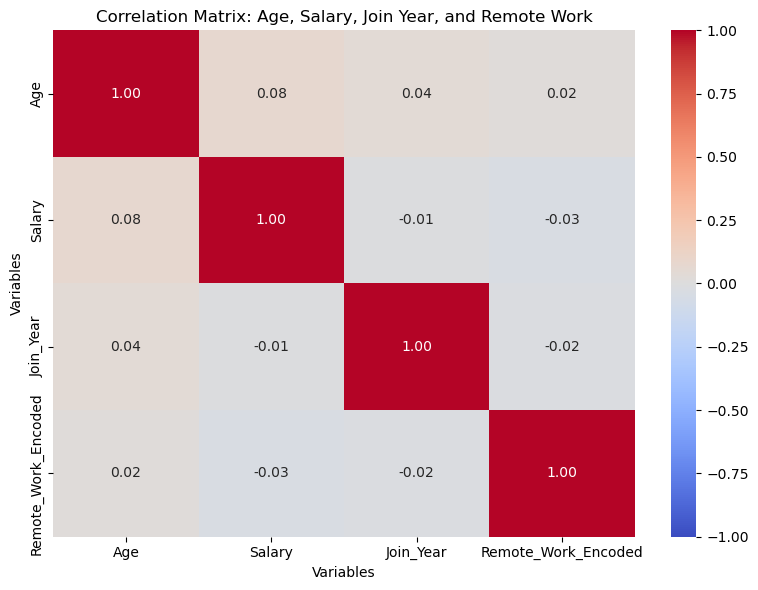

In [9]:
# Create a broader correlation matrix using numeric variables and one binary flag
clean_df["Join_Year"] = clean_df["Join_Date"].dt.year
clean_df["Remote_Work_Encoded"] = clean_df["Remote_Work"].astype(int)

numeric_cols = ["Age", "Salary", "Join_Year", "Remote_Work_Encoded"]
numeric_corr = clean_df[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(numeric_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation Matrix: Age, Salary, Join Year, and Remote Work")
plt.xlabel("Variables")
plt.ylabel("Variables")
plt.tight_layout()
plt.show()


**Correlation Comment:** The matrix compares four numeric/encoded variables: age, salary, joining year, and remote-work status (False = 0, True = 1). The age–salary correlation is approximately **0.077**, a very weak positive linear relationship. Correlations involving the encoded remote-work flag should be interpreted as simple group associations, not causal effects.

### Outlier Detection — Salary Using the IQR Method

In [10]:
Q1 = clean_df["Salary"].quantile(0.25)
Q3 = clean_df["Salary"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

salary_outliers = clean_df[
    (clean_df["Salary"] < lower_bound) |
    (clean_df["Salary"] > upper_bound)
]

print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Lower bound:", round(lower_bound, 2))
print("Upper bound:", round(upper_bound, 2))
print("Number of salary outliers:", len(salary_outliers))


Q1: 68811.23
Q3: 100372.66
IQR: 31561.43
Lower bound: 21469.09
Upper bound: 147714.81
Number of salary outliers: 0


**Outlier Comment:** Using the IQR rule, this dataset flags **0 salary outliers** after missing salaries are filled with the median. This means no salary values fall outside the calculated 1.5×IQR limits; it does not prove that every salary is correct or fair.

## 4. LINEAR REGRESSION

### Predicting Salary from Age

Linear regression can be used to examine whether there is a linear relationship between employee age and salary. The model estimates salary from age.

> **Note:** This is an association/prediction exercise, not proof that age causes salary differences.


In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Prepare the variables
X = clean_df[["Age"]]
y = clean_df["Salary"]

# Build and fit the linear regression model
model = LinearRegression()
model.fit(X, y)

# Make predictions
y_pred = model.predict(X)

# Model results
slope = model.coef_[0]
intercept = model.intercept_
r2 = r2_score(y, y_pred)

print(f"Slope: ${slope:,.2f}")
print(f"Intercept: ${intercept:,.2f}")
print(f"R-squared: {r2:.3f}")


Slope: $293.46
Intercept: $75,782.33
R-squared: 0.006


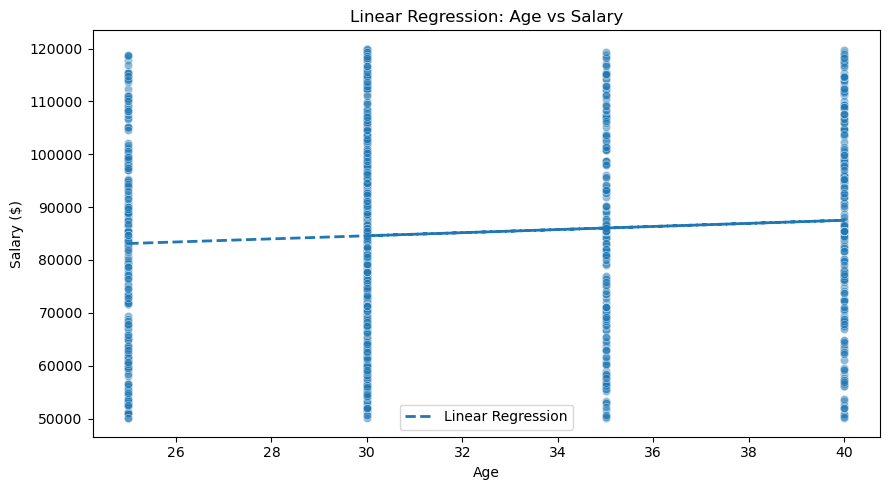

In [12]:
# Visualize the regression line
plt.figure(figsize=(9, 5))
sns.scatterplot(data=clean_df, x="Age", y="Salary", alpha=0.5)
plt.plot(
    clean_df["Age"],
    y_pred,
    linestyle="--",
    linewidth=2,
    label="Linear Regression"
)
plt.title("Linear Regression: Age vs Salary")
plt.xlabel("Age")
plt.ylabel("Salary ($)")
plt.legend()
plt.tight_layout()
plt.show()


### Linear Regression Comment

The model's **R-squared is approximately 0.006**, meaning age explains only about **0.6% of the observed variation in salary** in this simple model. The age–salary relationship is therefore extremely weak and age alone is not useful for estimating an employee's salary in this dataset. This is an important finding: salary prediction would likely need relevant variables such as job role, department, seniority, and experience, if available.

The model shows association, not causation, and should not be used by itself to make compensation decisions.

## 5. VISUALISATION

### Chart 1 — Average Salary by Department/Region

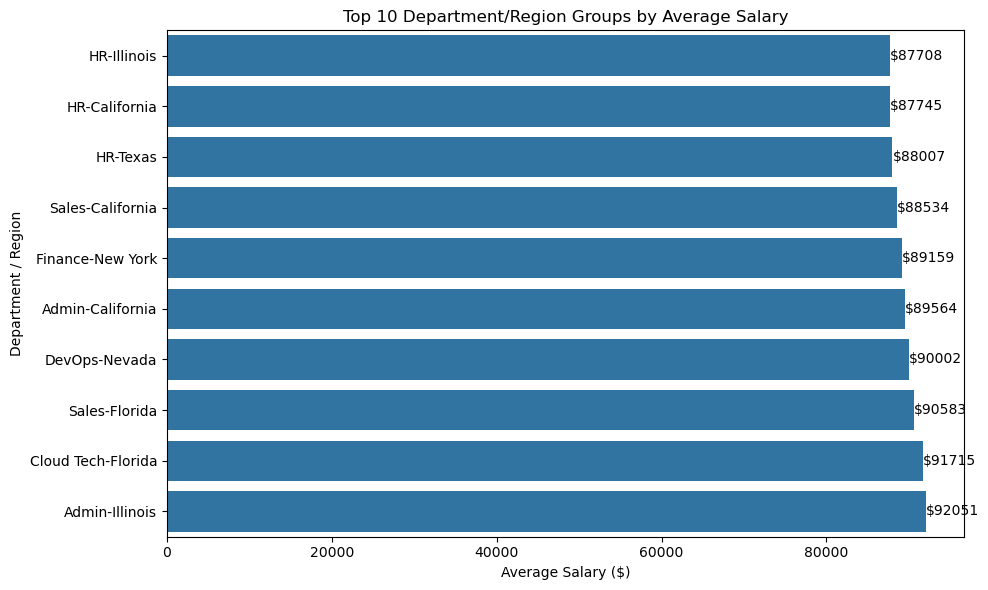

In [13]:
top_departments = department_salary.head(10).sort_values("mean")

plt.figure(figsize=(10, 6))
ax = sns.barplot(data=top_departments, x="mean", y="Department_Region")
plt.title("Top 10 Department/Region Groups by Average Salary")
plt.xlabel("Average Salary ($)")
plt.ylabel("Department / Region")

for container in ax.containers:
    ax.bar_label(container, fmt="$%.0f")

plt.tight_layout()
plt.show()


**Chart Comment:** The bar chart compares average salary for the 10 highest-paying department/region groups. Admin–Illinois is the highest group overall at about **$92,051**, while Finance–Illinois is the lowest group overall at about **$75,708**. The chart helps show that salary averages differ across groups, but it does not explain why.

### Chart 2 — Salary Distribution

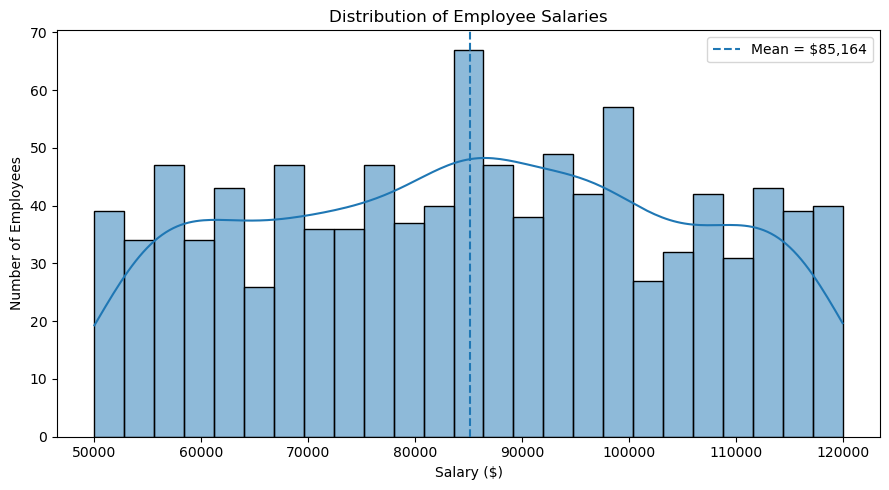

In [14]:
plt.figure(figsize=(9, 5))
sns.histplot(clean_df["Salary"], bins=25, kde=True)
plt.axvline(
    clean_df["Salary"].mean(),
    linestyle="--",
    label=f"Mean = ${clean_df['Salary'].mean():,.0f}"
)
plt.title("Distribution of Employee Salaries")
plt.xlabel("Salary ($)")
plt.ylabel("Number of Employees")
plt.legend()
plt.tight_layout()
plt.show()


**Chart Comment:** The dataset's mean salary after cleaning is approximately **$85,164**, and the median is **$85,548**. The histogram shows how employee salaries are distributed around the center and whether the distribution is skewed. Missing salaries were filled with the median, so that should be kept in mind when interpreting the shape.

### Chart 3 — Salary by Remote-Work Status

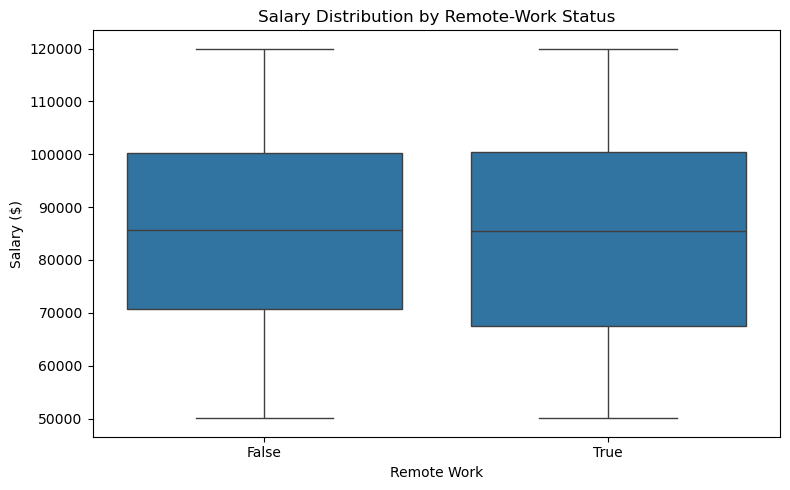

In [15]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_df, x="Remote_Work", y="Salary")
plt.title("Salary Distribution by Remote-Work Status")
plt.xlabel("Remote Work")
plt.ylabel("Salary ($)")
plt.tight_layout()
plt.show()


**Chart Comment:** The box plot compares salary spread for **513 remote employees** and **507 non-remote employees**. Their average salaries are about **$84,501** and **$85,835**, respectively. The distributions overlap, so remote-work status by itself should not be treated as an explanation for pay differences.

### Chart 4 — Subplot Grid

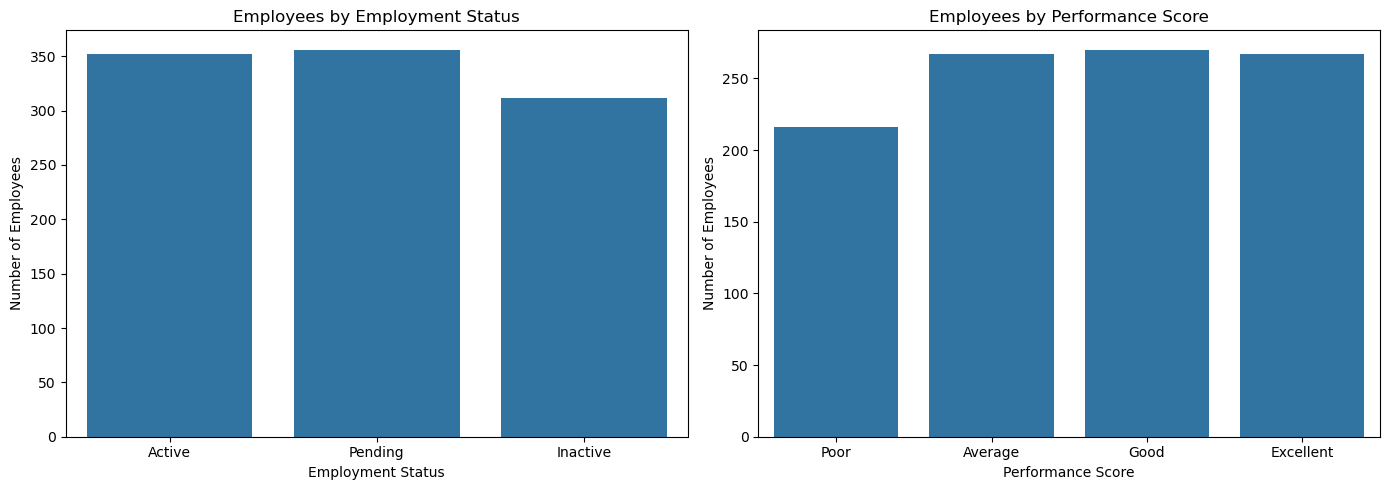

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1
sns.countplot(data=clean_df, x="Status", ax=axes[0])
axes[0].set_title("Employees by Employment Status")
axes[0].set_xlabel("Employment Status")
axes[0].set_ylabel("Number of Employees")

# Plot 2
sns.countplot(
    data=clean_df,
    x="Performance_Score",
    order=["Poor", "Average", "Good", "Excellent"],
    ax=axes[1]
)
axes[1].set_title("Employees by Performance Score")
axes[1].set_xlabel("Performance Score")
axes[1].set_ylabel("Number of Employees")

plt.tight_layout()
plt.show()


**Chart Comment:** The left plot compares counts across employment statuses: **356 Pending**, **352 Active**, and **312 Inactive**. The right plot shows performance-score counts: **216 Poor**, **267 Average**, **270 Good**, and **267 Excellent**. This gives HR a quick view of workforce composition; counts alone do not explain performance or employment outcomes.

### Chart 5 — Joining Trend

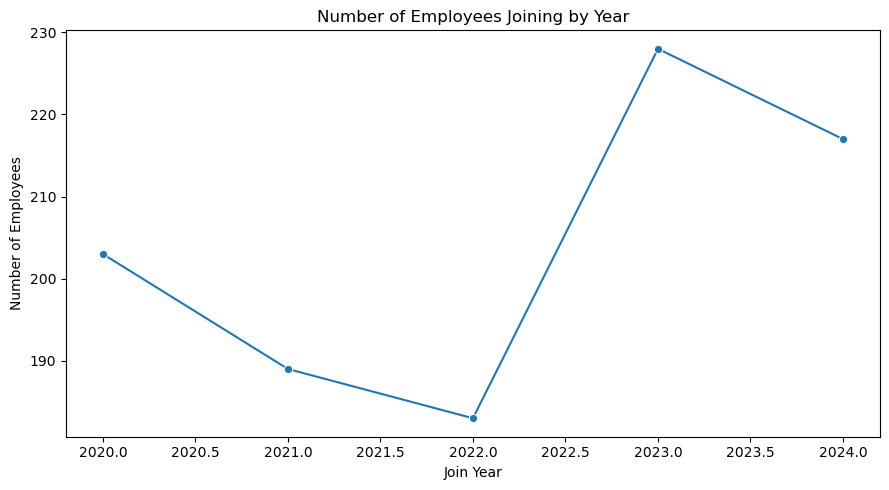

In [17]:
join_trend = (
    clean_df.assign(Join_Year=clean_df["Join_Date"].dt.year)
    .groupby("Join_Year")
    .size()
    .reset_index(name="Employees_Joined")
)

plt.figure(figsize=(9, 5))
sns.lineplot(data=join_trend, x="Join_Year", y="Employees_Joined", marker="o")
plt.title("Number of Employees Joining by Year")
plt.xlabel("Join Year")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()


**Chart Comment:** The line chart counts employee joining dates by year from **2020 through 2024**. Use the year-to-year pattern to identify periods with more or fewer joiners. These are counts from the supplied dataset and may not represent the company's full historical hiring if the file is only a sample.

## 6. BUSINESS STORY

### Context
The dataset contains **1,020 employee records** across **12 columns**. There are **211 missing Age values** and **24 missing Salary values** before cleaning. The median age (**30 years**) and median salary (**$85,547.87**) were used to fill those missing values. No exact duplicate rows were found.

### Finding
Average salary varies by department/region. **Admin–Illinois** has the highest group average at approximately **$92,051** (29 employees), while **Finance–Illinois** has the lowest at approximately **$75,708** (33 employees), a difference of about **$16,343**. Average salary is approximately **$84,501 for remote employees** and **$85,835 for non-remote employees**, a gap of about **$1,334**.

### Deeper Finding
The age-to-salary linear regression has an **R-squared of 0.006**, so age explains only about **0.6%** of salary variation. The age–salary correlation is approximately **0.077**, also indicating a very weak positive linear relationship. The IQR method identified **0 salary outliers** after missing salaries were filled. These results suggest that age alone is not a useful salary predictor and that the department/region differences deserve more investigation.

### Recommendation
HR should compare salaries within similar job roles, seniority levels, and locations instead of using age as a salary predictor. Investigate the approximately **$16,343** difference between the highest- and lowest-average department/region groups to determine whether job mix or other legitimate factors explain it. Review remote/non-remote pay only after controlling for department and role. Do not treat group averages as proof of unfairness or causation.

## 7. CAUSE / EFFECT / BUSINESS IMPACT

### Cause
Employees are distributed across different department/region groups and work arrangements. The dataset also has limited predictive information for salary: age has a correlation of only **0.077** with salary.

### Effect
Average salary ranges from about **$75,708** in Finance–Illinois to about **$92,051** in Admin–Illinois, a difference of approximately **$16,343**. Remote employees average about **$84,501**, compared with **$85,835** for non-remote employees. The age-only regression has an **R-squared of 0.006**, meaning age explains only around **0.6%** of salary variation.

### Business Impact
HR can use these results to prioritize a deeper pay review by comparable role, level, and location. The low R-squared is a warning not to use age alone for salary prediction. Reviewing the underlying job mix and compensation bands may help explain group differences and support better workforce planning.

> **Important:** These are descriptive associations. The analysis does not establish that department, remote work, or age causes salary differences.

## 8. CONCLUSION

This project demonstrates a complete data analytics workflow:


- Cleaned missing values
- Checked and removed duplicate records
- Corrected data types
- Treated phone numbers appropriately as identifiers
- Performed multiple GroupBy analyses
- Built a correlation matrix
- Detected salary outliers using IQR
- Created more than 4 visualizations
- Created a subplot grid
- Added chart titles and labelled axes
- Built a business story
- Applied the Cause / Effect / Business Impact framework

### Skills Demonstrated
**Python • Pandas • Matplotlib • Seaborn • Data Cleaning • EDA • GroupBy • Correlation • Outlier Detection • Linear Regression • Data Visualization • Business Storytelling**
